# The X-series: seven attempts to improve cross-camera glaucoma prediction

**Question.** The cup-to-disc ratios rank glaucoma well on CHAKSU (AUC 0.943) but poorly on PAPILA (0.731), a different camera and hospital. Can a principled change close the gap?

The design and decision rules were written before any experiment ran (`docs/experiment_log.md`, "X-series design"). A variant first had to pass a development gate (train on one camera, score two others) and only then was frozen and scored once on each test set. This notebook reads only the saved result tables in `docs/x_evidence/`; it opens no image and no model. The write-up is `docs/x_series.md`.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from glaucoma_project import REPO_ROOT

EVIDENCE = REPO_ROOT / "docs" / "x_evidence"
def gate(name):
    return json.loads((EVIDENCE / name / "gate.json").read_text())
pd.set_option("display.width", 160)

## 1. Development gates
Train on Remidio only, score the Bosch and Forus development images (198 images, 35 glaucoma). The variant passes if it beats its baseline. A failed variant is never scored on a test set.

In [2]:
rows = []
for name, label in (("x2", "X2 disc-centred crop"), ("x3", "X3 strong colour augmentation"),
                    ("x4", "X4 DINOv2 backbone"), ("x6", "X6 multi-task network")):
    g = gate(name)
    rows.append({"experiment": label, "metric": "mean AUC", "variant": g["variant"]["mean_auc"],
                 "baseline": g["baseline"]["mean_auc"], "passed": g["passes"]})
g = gate("x5")
rows.append({"experiment": "X5 robust segmentation", "metric": "mean Dice",
             "variant": g["variant"]["shifted_dice"], "baseline": g["baseline"]["shifted_dice"], "passed": g["passes"]})
gates = pd.DataFrame(rows)
gates.round(3)

,experiment,metric,variant,baseline,passed
0,X2 disc-centred crop,mean AUC,0.804,0.805,False
1,X3 strong colour augmentation,mean AUC,0.776,0.805,False
2,X4 DINOv2 backbone,mean AUC,0.680,0.805,False
3,X6 multi-task network,mean AUC,0.831,0.805,True
4,X5 robust segmentation,mean Dice,0.936,0.932,True


**Reading.** X2, X3 and X4 failed and were dropped. X5 and X6 passed. A pass is permission to test, not a result: the gate has 35 positives and CHAKSU's label convention.

## 2. Test results
Each variant against its fixed reference, with a paired bootstrap over patient groups (2,000 resamples). An improvement is claimed only if the 95% interval excludes 0.

In [3]:
def primary(name, partition_col="partition"):
    table = pd.read_csv(EVIDENCE / name / "primary.csv")
    return table.rename(columns={"split": "partition"})

x5 = pd.read_csv(EVIDENCE / "x5" / "comparison.csv").rename(columns={"split": "partition"})
frames = {"X5 robust segmentation minus Baseline A": x5,
          "X6 multi-task minus P01 image-only": primary("x6"),
          "X7 blend minus X5 measurements only": primary("x7")}
results = pd.concat([f.assign(comparison=name)[["comparison", "partition", "difference", "ci_low", "ci_high"]]
                     for name, f in frames.items()], ignore_index=True)
results["excludes_zero"] = (results.ci_low > 0) | (results.ci_high < 0)
results.round(3)

,comparison,partition,difference,ci_low,ci_high,excludes_zero
0,X5 robust segmentation minus Baseline A,in_domain_test,-0.011,-0.040,0.015,False
1,X5 robust segmentation minus Baseline A,external_test,0.092,0.036,0.151,True
2,X6 multi-task minus P01 image-only,in_domain_test,0.040,-0.009,0.090,False
3,X6 multi-task minus P01 image-only,external_test,-0.111,-0.181,-0.039,True
4,X7 blend minus X5 measurements only,in_domain_test,-0.003,-0.012,0.005,False
5,X7 blend minus X5 measurements only,external_test,0.002,-0.006,0.011,False


In [4]:
x1 = pd.read_csv(EVIDENCE / "x1" / "comparison.csv")
x1[x1.partition == "external_test"].round(3)

,partition,metric,raw,standardised,difference,ci_low,ci_high,n_images,n_positives
0,external_test,balanced_accuracy,0.702,0.649,-0.053,-0.111,-0.001,420,87
1,external_test,auc,0.745,0.749,0.005,-0.002,0.013,420,87


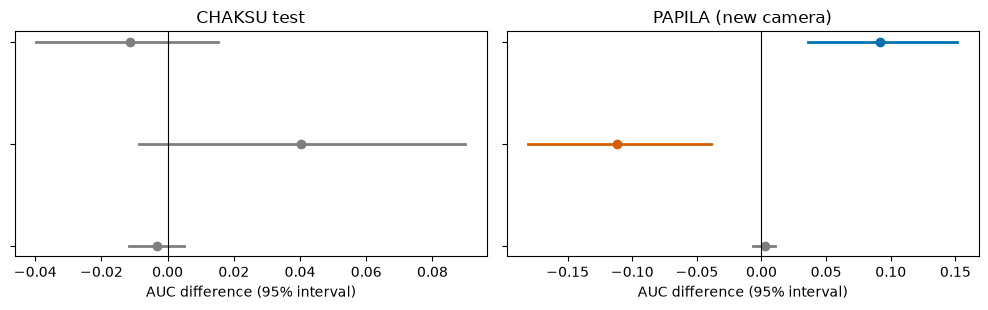

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
names = list(results.comparison.unique())[::-1]
for ax, partition, title in zip(axes, ["in_domain_test", "external_test"], ["CHAKSU test", "PAPILA (new camera)"]):
    part = results[results.partition == partition].set_index("comparison").loc[names]
    for y, (name, row) in enumerate(part.iterrows()):
        color = "#0072B2" if row.excludes_zero and row["difference"] > 0 else ("#D55E00" if row.excludes_zero else "#7f7f7f")
        ax.plot([row.ci_low, row.ci_high], [y, y], color=color, lw=2)
        ax.plot(row["difference"], y, "o", color=color)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(title); ax.set_xlabel("AUC difference (95% interval)")
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names if partition == "in_domain_test" else [])
fig.tight_layout()
plt.show()

**Reading.** Blue means the interval is above 0, orange below, grey includes 0.
- **X5** is the only improvement: PAPILA AUC 0.823 against 0.731. On CHAKSU it is unchanged.
- **X6** is worse than the image-only model on PAPILA, although it passed the gate.
- **X7** adds nothing over the X5 ratios alone.
- X1 (standardising the ratios) left AUC unchanged and moved the PAPILA operating point the wrong way (table above).

## 3. What X5 did

X5 retrained the disc and cup network with random rescaling (0.6 to 1.6) and stronger colour changes, and re-estimated its batch-norm statistics on each new set of photographs. On PAPILA the outlines improved a lot, and the unchanged classifier on top ranked better.

In [6]:
seg = pd.read_csv(EVIDENCE / "x5" / "segmentation.csv")
seg.round(3)

,split,adapted,dice_disc,dice_cup,vcdr_mae,vcdr_pearson
0,in_domain_test,True,0.972,0.915,0.035,0.758
1,external_test,True,0.926,0.535,0.172,0.810
2,in_domain_test,False,0.972,0.916,0.035,0.779
3,external_test,False,0.923,0.536,0.168,0.802


For reference, frozen Baseline A on PAPILA had disc Dice 0.800, cup Dice 0.458 and a vertical-CDR error of 0.215 (`docs/baseline_a.md`). Batch-norm adaptation changed almost nothing (compare the two `adapted` rows), so the gain comes from the augmentation: this is domain generalisation by augmentation, not domain adaptation.

## 4. Limits
- One trained segmentation network for X5. The intervals cover test-image sampling only.
- Both test sets were used by earlier experiments, and the series makes 8 primary test comparisons, so any win is exploratory.
- At the development threshold X5 flags only 51% of PAPILA glaucoma eyes (specificity 98%): the ranking improved, the cutoff does not transfer.